<a href="https://colab.research.google.com/github/karen-tran08/walmart-hurricane-project/blob/main/notebooks/team_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Walmart Hurricane Analytics: DS2002 Midterm Project

**Team:** The Cleaners · Karen Tran ([karen-tran08](https://github.com/karen-tran08)) · Zach Bernas ([Zakattak0](https://github.com/Zakattak0))
**Course:** DS2002 Data Science Systems, Fall 2026 · [Team charter](../CHARTER.md)

Walmart leadership wants to know what Florida shoppers buy before a hurricane. We clean five messy data sources, join them to real weather from the Open-Meteo API, and answer five questions about Hurricane Helene (landfall **September 26, 2024**).

**Contents**
1. Setup and data loading
2. Profiling the raw data (the mess)
3. Cleaning pipeline
4. Decision log
5. Weather API integration
6. Q1: Demand surge
7. Q2: The Pop-Tarts effect (SKU consolidation)
8. Q3: Weather correlation and lag
9. Q4: Store-level geographic patterns
10. Q5: Board games, signal or artifact?
11. Recommendation summary
12. Reflection

## 1. Setup and data loading

All work is in Python with pandas, matplotlib/seaborn, sqlite3, and requests. The notebook looks for the data in `../data/` (the repo layout). If it can't find it there, for example when running in Colab, it downloads the files from the team repo instead.

In [1]:
import os, re, time, sqlite3, tempfile
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 20)

REPO_RAW = 'https://raw.githubusercontent.com/karen-tran08/walmart-hurricane-project/main/data/'
DATA_DIR = next((d for d in ['../data/', 'data/', '../../data/'] if os.path.exists(d + 'walmart_transactions.csv')), None)

def data_path(name):
    # Local file if the repo is cloned, otherwise download it from the team repo once
    if DATA_DIR:
        return DATA_DIR + name
    local = os.path.join(tempfile.gettempdir(), name)
    if not os.path.exists(local):
        r = requests.get(REPO_RAW + name, timeout=30)
        r.raise_for_status()
        open(local, 'wb').write(r.content)
    return local

print('data source:', DATA_DIR or REPO_RAW)

data source: https://raw.githubusercontent.com/karen-tran08/walmart-hurricane-project/main/data/


In [2]:
raw_txns    = pd.read_csv(data_path('walmart_transactions.csv'), dtype=str)
raw_stores  = pd.read_csv(data_path('store_locations.csv'))
raw_catalog = pd.read_csv(data_path('product_catalog.csv'))
raw_dcs     = pd.read_csv(data_path('distribution_centers.csv'))

con = sqlite3.connect(data_path('inventory_and_sales.db'))
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table'", con)
raw_daily_summary = pd.read_sql('SELECT * FROM daily_sales_summary', con)
raw_inventory     = pd.read_sql('SELECT * FROM inventory_levels', con)

for name, df in [('walmart_transactions.csv', raw_txns), ('store_locations.csv', raw_stores),
                 ('product_catalog.csv', raw_catalog), ('distribution_centers.csv', raw_dcs),
                 ('db: daily_sales_summary', raw_daily_summary), ('db: inventory_levels', raw_inventory)]:
    print(f'{name:<28} {df.shape[0]:>6,} rows x {df.shape[1]} cols')

walmart_transactions.csv     25,562 rows x 8 cols
store_locations.csv              14 rows x 8 cols
product_catalog.csv              45 rows x 7 cols
distribution_centers.csv          5 rows x 8 cols
db: daily_sales_summary       3,600 rows x 5 cols
db: inventory_levels          4,320 rows x 6 cols


## 2. Profiling the raw data

Before cleaning anything we measure the problems. Every number below is computed from the raw files, so the cleaning steps in Section 3 can be checked against it.

In [3]:
t = raw_txns
qty = pd.to_numeric(t['quantity'], errors='coerce')
profile = {
    'rows': len(t),
    'exact duplicate rows': t.duplicated().sum(),
    'duplicate transaction_id': t['transaction_id'].duplicated().sum(),
    'missing timestamp': t['timestamp'].isna().sum(),
    'quantity <= 0': (qty <= 0).sum(),
    "unit_price containing '$'": t['unit_price'].str.contains(r'\$', na=False).sum(),
    'distinct store_id spellings': t['store_id'].nunique(),
    'distinct category spellings': t['category'].nunique(),
    'distinct SKUs': t['sku'].nunique(),
    'distinct product_name spellings': t['product_name'].nunique(),
}
display(pd.Series(profile, name='count').to_frame())

,count
rows,25562
exact duplicate rows,30
duplicate transaction_id,30
missing timestamp,886
quantity <= 0,130
unit_price containing '$',3029
distinct store_id spellings,60
distinct category spellings,37
distinct SKUs,45
distinct product_name spellings,63


In [4]:
# Standard first look: types and missing values (everything arrives as text; note the blank cells)
raw_txns.info()
print()
missing = pd.DataFrame({
    'NaN': raw_txns.isna().sum(),
    "'NULL' / 'N/A' / blank text": raw_txns.apply(lambda c: c.astype(str).str.strip().str.upper().isin(['NULL', 'N/A', 'NA', '']).sum()),
})
display(missing)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25562 entries, 0 to 25561
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   transaction_id  25562 non-null  object
 1   store_id        25562 non-null  object
 2   timestamp       24676 non-null  object
 3   sku             25562 non-null  object
 4   product_name    25562 non-null  object
 5   category        25562 non-null  object
 6   quantity        25562 non-null  object
 7   unit_price      25562 non-null  object
dtypes: object(8)
memory usage: 1.6+ MB



,NaN,'NULL' / 'N/A' / blank text
transaction_id,0,0
store_id,0,0
timestamp,886,0
sku,0,0
product_name,0,0
category,0,0
quantity,0,0
unit_price,0,0


In [5]:
# A sample of the mess: timestamp formats, store IDs, categories, prices
fmt = (t['timestamp'].dropna()
         .str.replace(r'\d', '9', regex=True)
         .value_counts().rename('rows'))
print('Timestamp formats (digits shown as 9):'); display(fmt.to_frame())
print('Store ID spellings:', sorted(t['store_id'].dropna().unique())[:15], '...')
print('Category spellings:', t['category'].nunique(), '->', sorted(t['category'].dropna().unique())[:12], '...')
print('Price examples:', t['unit_price'].dropna().sample(8, random_state=2).tolist())

Timestamp formats (digits shown as 9):


,rows
timestamp,
9999-99-99 99:99:99,12179
99/99/9999 99:99,5031
99-Sep-9999 99:99,2546
9999-99-99T99:99:99,2511
99-99-9999 99:99:99,2409


Store ID spellings: [' FL-078', ' FL-105', ' FL-156', ' FL-239', ' FL-287', ' FL-302', ' FL-330', ' FL-412', ' FL-445', ' FL-501', ' FL-619', ' FL-710', 'FL-078', 'FL-105', 'FL-156'] ...
Category spellings: 37 -> ['ALCOHOL', 'Alcohol', 'Alcoholic Beverages', 'BABY', 'BREAKFAST', 'Baby', 'Baby Products', 'Breakfast', 'Breakfast Foods', 'ELECTRONICS', 'EMERGENCY', 'ENTERTAINMENT'] ...
Price examples: ['6.77', '3.38', '15.18', '19.65', '25.23', '20.21', ' 14.86 ', '$10.24']


In [6]:
print('Store file: duplicate stores and messy fields')
display(raw_stores[['store_id', 'city', 'state', 'latitude', 'longitude', 'region']])

print('Product catalog: one product, many SKUs (Pop-Tarts example)')
display(raw_catalog[raw_catalog['product_name'].str.contains('pop', case=False)])

print('SQLite daily_sales_summary: date formats', raw_daily_summary['date'].str.len().value_counts().to_dict(),
      '| fractional unit counts:', (raw_daily_summary['total_units'] % 1 != 0).sum())
print('SQLite inventory_levels: SKUs not in catalog:',
      sorted(set(raw_inventory['sku']) - set(raw_catalog['sku'])),
      '| null units_on_order:', raw_inventory['units_on_order'].isna().sum())
print('Catalog: category spellings', raw_catalog['category'].nunique(), '| package_size formats', raw_catalog['package_size'].nunique(),
      '| missing unit_cost', raw_catalog['unit_cost'].isna().sum(), '| missing subcategory', raw_catalog['subcategory'].isna().sum())
print('Distribution centers:'); display(raw_dcs)

Store file: duplicate stores and messy fields


,store_id,city,state,latitude,longitude,region
0,FL-239,Orlando,FL,28.5383,-81.3792,Central
1,FL-105,Tampa,FL,27.9506,-82.4572,West
2,FL-330,Miami,FL,25.7617,-80.1918,South
3,FL-412,Jacksonville,FL,30.3322,-81.6557,North
4,FL-287,Kissimmee,Florida,28.2920,-81.4076,Central
5,FL-156,Daytona Beach,FL,29.2108,-81.0228,East
6,FL-501,Fort Myers,FL,26.6406,-81.8723,West
7,FL-078,Gainesville,FL,29.6516,-82.3248,North
8,FL-619,Tallahassee,FL,NaN,NaN,Panhandle
9,FL-445,St. Petersburg,Fla.,27.7676,-82.6403,West


Product catalog: one product, many SKUs (Pop-Tarts example)


,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack


SQLite daily_sales_summary: date formats {10: 3382, 8: 218} | fractional unit counts: 76
SQLite inventory_levels: SKUs not in catalog: ['LEGACY-PT', 'MISC-001', 'OLD-BATT-50', 'UNKNOWN-99'] | null units_on_order: 626
Catalog: category spellings 27 | package_size formats 15 | missing unit_cost 5 | missing subcategory 13
Distribution centers:


,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,~750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


## 3. Cleaning pipeline

All five data sources are cleaned here: the transactions, stores, product catalog, and distribution-center files, plus both SQLite tables. Every fix is a function, so the analysis sections never patch data themselves. The pipeline runs on the raw files every time. We don't load a saved cleaned CSV, so any change to a cleaning rule flows through to every answer.

Order matters: prices, quantities, timestamps, store IDs, and categories are standardized **before** de-duplication, so rows that differ only in formatting are caught as duplicates.

In [7]:
CATEGORY_MAP = {
    'emergency supplies': 'emergency', 'groceries': 'grocery',
    'games & entertainment': 'entertainment', 'household essentials': 'household',
    'baby products': 'baby', 'breakfast foods': 'breakfast',
    'alcoholic beverages': 'alcohol', 'health & wellness': 'health',
}

def clean_unit_price(df):
    # Strip '$', commas, and whitespace, then convert to float
    df = df.copy()
    df['unit_price'] = pd.to_numeric(df['unit_price'].astype(str).str.replace(r'[$,\s]', '', regex=True),
                                     errors='coerce')
    return df

def clean_quantity(df):
    # quantity arrives as text; rows with quantity <= 0 are returns or entry errors (decision 003)
    df = df.copy()
    df['quantity'] = pd.to_numeric(df['quantity'], errors='coerce')
    return df[df['quantity'] > 0].reset_index(drop=True)

def parse_timestamp(df):
    # Five mixed formats; month-first is the correct reading (see reflection Q1)
    df = df.copy()
    df['timestamp'] = pd.to_datetime(df['timestamp'], format='mixed', dayfirst=False, errors='coerce')
    return df

def normalize_store_id(value):
    # 'fl_302', 'FL302', ' fl-302' -> 'FL-302'
    if pd.isna(value):
        return value
    m = re.fullmatch(r'([A-Z]{2})[-_ ]?(\d+)', str(value).strip().upper())
    return f'{m.group(1)}-{m.group(2)}' if m else str(value).strip().upper()

def clean_category(df):
    # 37 spellings -> 10 categories
    df = df.copy()
    df['category'] = df['category'].str.strip().str.lower().replace(CATEGORY_MAP)
    return df

def clean_transactions(df):
    print(f'Starting transaction rows:  {len(df):,}')
    df = clean_unit_price(df)
    before = len(df); df = clean_quantity(df)
    print(f'  quantity <= 0 removed:    -{before - len(df):,}')
    df = parse_timestamp(df)
    df['store_id'] = df['store_id'].map(normalize_store_id)
    df = clean_category(df)
    before = len(df); df = df.drop_duplicates().reset_index(drop=True)
    print(f'  duplicates removed:       -{before - len(df):,}')
    print(f'Ending transaction rows:    {len(df):,}  (missing timestamps kept: {df["timestamp"].isna().sum():,})')
    return df

def clean_stores(stores):
    stores = stores.copy()
    stores['store_id'] = stores['store_id'].map(normalize_store_id)
    stores = stores.drop_duplicates(subset='store_id').reset_index(drop=True)
    stores['state'] = 'FL'                                  # 'FL', 'Florida', 'Fla.' are all Florida
    stores['region'] = stores['region'].str.strip()         # ' Panhandle' -> 'Panhandle'
    # Tallahassee (FL-619) has no coordinates; fill with the city's published coordinates (decision 007)
    stores.loc[stores['store_id'] == 'FL-619', ['latitude', 'longitude']] = [30.4383, -84.2807]
    return stores

SKU_TO_PRODUCT = {
    'PT-12': 'Pop-Tarts Strawberry', 'SKU#459812': 'Pop-Tarts Strawberry',
    'POPTART-STRAW': 'Pop-Tarts Strawberry', 'PT_STRAWBERRY': 'Pop-Tarts Strawberry',
    'WTR-24': 'Bottled Water 24-Pack', 'WATER24PK': 'Bottled Water 24-Pack', 'WTR_24PK': 'Bottled Water 24-Pack',
    'BATT-100': 'AA Batteries 4-Pack', 'BAT-AA4': 'AA Batteries 4-Pack', 'BATT_AA_4PK': 'AA Batteries 4-Pack',
    'BG-MONO': 'Monopoly Board Game', 'MONOPOLY-01': 'Monopoly Board Game', 'GAME-MONO': 'Monopoly Board Game',
    'FLASH-01': 'LED Flashlight', 'LED-FLASH': 'LED Flashlight',
    'BEER-24': 'Light Beer 24-Pack', 'LTBEER24': 'Light Beer 24-Pack',
    'CARDS-01': 'Playing Cards', 'PLAYCARD-STD': 'Playing Cards',
    'STREAM-01': 'Roku Streaming Stick', 'ROKU-STD': 'Roku Streaming Stick',
    'SOUP-CAN': 'Canned Soup', 'CNSOUP-01': 'Canned Soup',
    'BREAD-WH': 'White Bread', 'WHITEBREAD': 'White Bread',
    'PB-16': 'Peanut Butter 16oz', 'PNUTBTR-16': 'Peanut Butter 16oz',
    'CNDL-EM': 'Emergency Candles', 'CANDLE-EMRG': 'Emergency Candles',
    'FAID-01': 'First Aid Kit', 'FIRSTAID-KIT': 'First Aid Kit',
    'CHRG-PORT': 'Portable Phone Charger', 'PORTCHARGER': 'Portable Phone Charger',
    'CHIPS-VP': 'Chips Variety Pack', 'CHIPVARIETY': 'Chips Variety Pack',
    'PTOWEL-6': 'Paper Towels 6-Roll', 'PAPERTOWEL6': 'Paper Towels 6-Roll',
    'TP-12': 'Toilet Paper 12-Roll', 'TOILETPAPER12': 'Toilet Paper 12-Roll',
    'DIAP-S3': 'Diapers Size 3', 'DIAPERS-3': 'Diapers Size 3',
    'BFORM-01': 'Baby Formula', 'BABYFORMULA': 'Baby Formula',
    'TARP-HD': 'Heavy Duty Tarp', 'HDTARP-01': 'Heavy Duty Tarp',
}

def parse_pack_count(text):
    # '4-pack', '4pk', '4 pack' -> 4; 'single' -> 1; 'bundle' gives no count -> NaN
    t = str(text).strip().lower()
    if t == 'single':
        return 1
    m = re.match(r'(\d+)', t)
    return float(m.group(1)) if m else np.nan

def clean_catalog(cat):
    cat = cat.copy()
    cat['category'] = cat['category'].str.strip().str.lower().replace(CATEGORY_MAP)   # 27 spellings -> 10
    cat['product'] = cat['sku'].map(SKU_TO_PRODUCT)                                     # one name per product
    cat['pack_count'] = cat['package_size'].map(parse_pack_count)                       # 15 formats -> a number
    # Missing unit_cost: use the mean cost of the same product's other SKUs, and flag it (decision 012)
    cat['unit_cost_imputed'] = cat['unit_cost'].isna()
    cat['unit_cost'] = cat['unit_cost'].fillna(cat.groupby('product')['unit_cost'].transform('mean')).round(2)
    # subcategory is blank for 13 SKUs and supplier doesn't match the product (Pop-Tarts from 'Roku Inc'),
    # so neither column can be trusted; drop them rather than analyze bad values (decision 013)
    return cat.drop(columns=['subcategory', 'supplier'])

def clean_dcs(dcs):
    dcs = dcs.copy()
    raw_cap = dcs['surge_capacity'].astype(str).str.strip()
    dcs['surge_capacity_approx'] = raw_cap.str.startswith('~')                          # '~750' was an estimate
    dcs['surge_capacity'] = pd.to_numeric(raw_cap.str.lstrip('~'))
    # Birmingham has no cost_per_shipment: estimate it from the cost-vs-distance line of the other 4 DCs, and flag it
    known = dcs['cost_per_shipment'].notna()
    slope, intercept = np.polyfit(dcs.loc[known, 'distance_to_orlando_mi'], dcs.loc[known, 'cost_per_shipment'], 1)
    dcs['cost_estimated'] = ~known
    dcs.loc[~known, 'cost_per_shipment'] = (intercept + slope * dcs.loc[~known, 'distance_to_orlando_mi']).round(2)
    return dcs

def clean_daily_summary(df):
    df = df.copy()
    df['date'] = pd.to_datetime(df['date'], format='mixed')   # '2024-09-14' and '20240914'
    df['store_id'] = df['store_id'].map(normalize_store_id)
    # 76 rows have fractional unit counts (e.g. 71.5); units are whole items, so round them (decision 014)
    df['total_units'] = df['total_units'].round().astype(int)
    return df

def clean_inventory(df):
    df = df.copy()
    df['date'] = pd.to_datetime(df['date'])
    df['store_id'] = df['store_id'].map(normalize_store_id)
    # 626 blank units_on_order: unknown, not zero, so they stay NaN and are never summed (decision 015)
    # 4 SKUs are not in the catalog; flag them so product analyses can leave them out (decision 010)
    df['in_catalog'] = df['sku'].isin(SKU_TO_PRODUCT)
    return df

txns = clean_transactions(raw_txns)
stores = clean_stores(raw_stores)
daily_summary = clean_daily_summary(raw_daily_summary)
inventory = clean_inventory(raw_inventory)
catalog = clean_catalog(raw_catalog)
dcs = clean_dcs(raw_dcs)

print()
print('Cleaned product catalog (first 8 SKUs):')
display(catalog.head(8))
print('Cleaned distribution centers:')
display(dcs)

Starting transaction rows:  25,562
  quantity <= 0 removed:    -130
  duplicates removed:       -30
Ending transaction rows:    25,402  (missing timestamps kept: 881)

Cleaned product catalog (first 8 SKUs):


,sku,product_name,category,unit_cost,package_size,product,pack_count,unit_cost_imputed
0,PT-12,pop-tarts strawberry,breakfast,1.93,4-pack,Pop-Tarts Strawberry,4.0,False
1,SKU#459812,Strawberry Pop-Tart,breakfast,2.26,4pk,Pop-Tarts Strawberry,4.0,False
2,POPTART-STRAW,Pop-Tarts Strawberry,breakfast,2.11,6 pack,Pop-Tarts Strawberry,6.0,False
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,2.10,4 pack,Pop-Tarts Strawberry,4.0,True
4,WTR-24,BOTTLED WATER 24PK,emergency,2.64,1 pack,Bottled Water 24-Pack,1.0,False
5,WATER24PK,Bottled Water 24-Pack,emergency,2.38,24 pack,Bottled Water 24-Pack,24.0,False
6,WTR_24PK,Water - 24 Pack,emergency,2.08,1 pack,Bottled Water 24-Pack,1.0,False
7,BATT-100,BATTERIES AA 4PK,emergency,3.94,6 pack,AA Batteries 4-Pack,6.0,True


Cleaned distribution centers:


,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment,surge_capacity_approx,cost_estimated
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.00,False,False
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.50,False,False
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.00,False,False
3,DC-MIA,Miami Distribution Center,Miami,FL,350,750,235,298.00,True,False
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,420.76,False,True


### Validating the cleaned data

These assertions stop the notebook if a cleaning step silently breaks. A wrong number then can't reach the analysis without anyone noticing.

In [8]:
def validate_clean(txns, stores):
    assert len(txns) == 25_402, f'expected 25,402 rows, got {len(txns):,}'
    assert txns['quantity'].sum() == 49_584, 'unit total changed'
    assert not txns.duplicated().any(), 'duplicates remain'
    assert (txns['quantity'] > 0).all()
    assert txns['unit_price'].notna().all() and txns['unit_price'].dtype == float
    assert set(txns['store_id']) <= set(stores['store_id']), 'store IDs that will not join'
    assert txns['category'].nunique() == 10
    assert len(stores) == 12 and stores[['latitude', 'longitude']].notna().all().all()
    print('Transactions and stores: 25,402 rows, 49,584 units, 12 stores, 10 categories, no duplicates.')

def validate_other(catalog, dcs, daily_summary, inventory, txns):
    assert len(catalog) == 45 and catalog['category'].nunique() == 10 and catalog['unit_cost'].notna().all()
    # Every SKU's catalog category must agree with the category on its transactions
    txn_cat = txns.groupby('sku')['category'].agg(lambda c: c.unique().tolist())
    mismatch = [s for s, cats in txn_cat.items() if cats != [catalog.set_index('sku').loc[s, 'category']]]
    assert not mismatch, f'catalog and transactions disagree on: {mismatch}'
    assert dcs['surge_capacity'].dtype.kind in 'if' and dcs['cost_per_shipment'].notna().all()
    assert daily_summary['date'].nunique() == 30 and daily_summary['total_units'].dtype.kind == 'i'
    assert not daily_summary.duplicated(['date', 'store_id', 'category']).any()
    assert not inventory.duplicated(['date', 'store_id', 'sku']).any()
    assert set(daily_summary['store_id']) == set(inventory['store_id']) == set(stores['store_id'])
    print('Catalog, distribution centers, and SQLite tables: 45 SKUs in 10 categories, 5 DCs, 30 days, 12 stores, no duplicates.')

validate_clean(txns, stores)
validate_other(catalog, dcs, daily_summary, inventory, txns)

# Rows with no timestamp keep their units in product totals (Q2) but are left out of daily analyses
dated = txns.dropna(subset=['timestamp']).copy()
dated['date'] = dated['timestamp'].dt.normalize()
print(f'Rows with a timestamp, used in daily analyses: {len(dated):,}')

Transactions and stores: 25,402 rows, 49,584 units, 12 stores, 10 categories, no duplicates.
Catalog, distribution centers, and SQLite tables: 45 SKUs in 10 categories, 5 DCs, 30 days, 12 stores, no duplicates.
Rows with a timestamp, used in daily analyses: 24,521


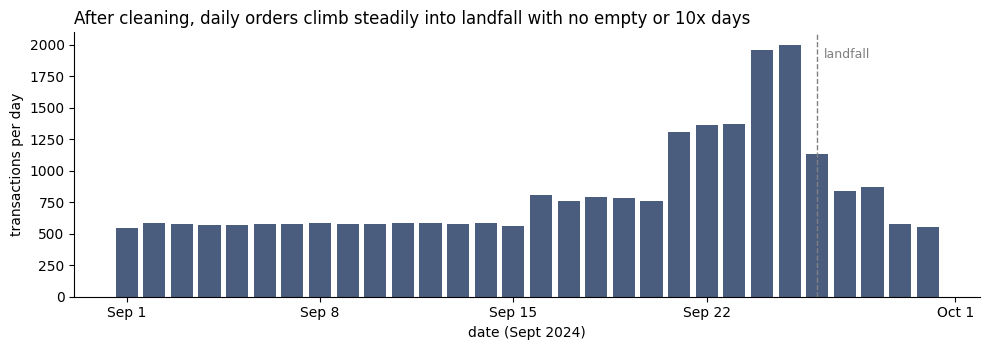

In [9]:
# Daily order volume after cleaning: a sanity check that the shape makes sense
daily_orders = dated.groupby('date').size()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(daily_orders.index, daily_orders.values, color='#4a5d7e')
ax.axvline(pd.Timestamp('2024-09-26'), ls='--', color='gray', lw=1)
ax.text(pd.Timestamp('2024-09-26 06:00'), daily_orders.max() * 0.95, 'landfall', color='gray', fontsize=9)
ax.set_title('After cleaning, daily orders climb steadily into landfall with no empty or 10x days',
             loc='left', fontsize=12)
ax.set_xlabel('date (Sept 2024)'); ax.set_ylabel('transactions per day')
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22])); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %-d'))
for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## 4. Decision log

Every cleaning decision, what it did, and how many rows it touched.

In [10]:
decision_log = pd.DataFrame([
    ('001', 'Remove exact duplicate rows (after standardizing formats)', '30 rows removed'),
    ('002', "Strip '$' and commas from unit_price, convert to float", "3,029 values contained '$'"),
    ('003', 'Drop rows with quantity <= 0 (returns / entry errors)', '130 rows removed (-241 units); surge is 2.89x with or without them'),
    ('004', 'Parse 5 mixed timestamp formats month-first; keep rows with missing timestamps',
            '881 rows kept for product totals, excluded from daily analyses'),
    ('005', 'Normalize store IDs (FL302, fl_302 -> FL-302); de-duplicate store file',
            '4,327 transactions normalized; 14 -> 12 stores'),
    ('006', 'Map 37 category spellings to 10 categories', 'all 25,402 rows'),
    ('007', 'Fill missing Tallahassee (FL-619) coordinates; normalize state and region', '1 store'),
    ('008', 'Consolidate 45 SKUs into 20 canonical products (SKU_TO_PRODUCT table, Q2)', 'all rows; unit total unchanged'),
    ('009', 'Parse mixed date formats in the SQLite daily_sales_summary', '218 rows in YYYYMMDD format'),
    ('010', 'Flag 4 inventory SKUs not in the catalog (LEGACY-PT, MISC-001, UNKNOWN-99, OLD-BATT-50)',
            f'{(~inventory["in_catalog"]).sum()} inventory rows flagged; excluded from product analyses'),
    ('011', 'Catalog: map 27 category spellings to the same 10 categories; one product name per SKU family; '
            'parse 15 package_size formats into a pack count', '45 SKUs'),
    ('012', 'Catalog: fill missing unit_cost with the mean of the same product\'s other SKUs (flagged)',
            f'{catalog["unit_cost_imputed"].sum()} SKUs'),
    ('013', 'Catalog: drop subcategory (13 blanks) and supplier (does not match products); '
            'pack sizes conflict within products (Pop-Tarts 4 vs 6), so they are not used in analysis', '45 SKUs'),
    ('014', 'SQLite daily_sales_summary: round fractional unit counts to whole units', '76 rows'),
    ('015', 'SQLite inventory_levels: keep blank units_on_order as unknown (NaN), never as 0', '626 rows'),
    ('016', "Distribution centers: '~750' surge capacity to 750 (flagged approximate); "
            'estimate Birmingham cost_per_shipment from cost vs distance of the other DCs (flagged)', '2 DCs'),
], columns=['#', 'decision', 'rows affected'])
with pd.option_context('display.max_colwidth', None):
    display(decision_log)

,#,decision,rows affected
0,001,Remove exact duplicate rows (after standardizing formats),30 rows removed
1,002,"Strip '$' and commas from unit_price, convert to float","3,029 values contained '$'"
2,003,Drop rows with quantity <= 0 (returns / entry errors),130 rows removed (-241 units); surge is 2.89x with or without them
3,004,Parse 5 mixed timestamp formats month-first; keep rows with missing timestamps,"881 rows kept for product totals, excluded from daily analyses"
4,005,"Normalize store IDs (FL302, fl_302 -> FL-302); de-duplicate store file","4,327 transactions normalized; 14 -> 12 stores"
5,006,Map 37 category spellings to 10 categories,"all 25,402 rows"
6,007,Fill missing Tallahassee (FL-619) coordinates; normalize state and region,1 store
7,008,"Consolidate 45 SKUs into 20 canonical products (SKU_TO_PRODUCT table, Q2)",all rows; unit total unchanged
8,009,Parse mixed date formats in the SQLite daily_sales_summary,218 rows in YYYYMMDD format
9,010,"Flag 4 inventory SKUs not in the catalog (LEGACY-PT, MISC-001, UNKNOWN-99, OLD-BATT-50)",355 inventory rows flagged; excluded from product analyses


## 5. Weather API integration

**Source:** [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), base URL `https://archive-api.open-meteo.com/v1/archive`

**Location:** Orlando (28.54, -81.38). It's central to our 12 stores, and we use it as the statewide weather signal. That limitation is discussed in Q3.

**Timezones:** We request **hourly** data in **UTC** (`timezone=GMT`), convert it to `America/New_York` (EDT in September), and only then aggregate to calendar days. If we grouped by UTC date instead, the hours from 8 p.m. to midnight Eastern would land on the next day's sales, which is exactly the timezone misalignment the brief warns about.

The call retries on timeouts and rate limits. There is no fallback data: if the API fails, the notebook stops rather than analyzing made-up weather.

In [11]:
WEATHER_URL = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def fetch_hourly_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat, 'longitude': lon, 'start_date': start, 'end_date': end,
        'hourly': 'wind_speed_10m,precipitation,pressure_msl',
        'timezone': 'GMT',
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(WEATHER_URL, params=params, timeout=15)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt); continue
        if r.status_code in RETRY_STATUSES and attempt < tries:
            time.sleep(2 ** attempt); continue
        r.raise_for_status()
        frame = pd.DataFrame(r.json()['hourly'])
        frame['time_utc'] = pd.to_datetime(frame.pop('time')).dt.tz_localize('UTC')
        frame['source'] = 'open-meteo'
        return frame

# Pull one extra day on each side so every Eastern-time day is complete after conversion
hourly = fetch_hourly_weather('2024-08-31', '2024-10-01')
print(f'hourly rows returned: {len(hourly):,} | source: {hourly["source"].iloc[0]}')
display(hourly.head(3))

hourly rows returned: 768 | source: open-meteo


,wind_speed_10m,precipitation,pressure_msl,time_utc,source
0,5.0,0.0,1017.4,2024-08-31 00:00:00+00:00,open-meteo
1,6.1,0.0,1017.8,2024-08-31 01:00:00+00:00,open-meteo
2,5.4,0.0,1018.3,2024-08-31 02:00:00+00:00,open-meteo


In [12]:
# UTC -> Eastern, then aggregate to the same calendar days as the sales data
hourly['time_local'] = hourly['time_utc'].dt.tz_convert('America/New_York')
hourly['date'] = hourly['time_local'].dt.tz_localize(None).dt.normalize()

weather = (hourly.groupby('date')
                 .agg(wind_max_kmh=('wind_speed_10m', 'max'),
                      precip_mm=('precipitation', 'sum'),
                      pressure_min_hpa=('pressure_msl', 'min'))
                 .loc['2024-09-01':'2024-09-30']
                 .reset_index())

shifted = (hourly['time_utc'].dt.normalize().dt.tz_localize(None) != hourly['date']).sum()
print(f'{shifted} of {len(hourly)} hourly readings fall on a different calendar day in Eastern time than in UTC')
print(f'daily weather rows: {len(weather)} (Sept 1-30)')
display(weather.head())

128 of 768 hourly readings fall on a different calendar day in Eastern time than in UTC
daily weather rows: 30 (Sept 1-30)


,date,wind_max_kmh,precip_mm,pressure_min_hpa
0,2024-09-01,18.8,3.0,1012.8
1,2024-09-02,13.5,12.4,1013.0
2,2024-09-03,22.8,24.8,1014.3
3,2024-09-04,15.5,22.1,1016.6
4,2024-09-05,15.2,22.7,1014.9


In [13]:
# Join to daily sales and prove nothing was lost
daily_sales = (dated.groupby('date')
                    .agg(orders=('transaction_id', 'size'), units=('quantity', 'sum'))
                    .reset_index())
merged = daily_sales.merge(weather, on='date', how='left', validate='one_to_one', indicator=True)

assert len(merged) == len(daily_sales), 'join changed the row count'
assert (merged['_merge'] == 'both').all(), 'some sales days have no weather'
assert merged['units'].sum() == daily_sales['units'].sum()
merged = merged.drop(columns='_merge')
print(f'rows before join: {len(daily_sales)} | after: {len(merged)} | units preserved: {merged["units"].sum():,}')

rows before join: 30 | after: 30 | units preserved: 47,897


## 6. Q1: Demand surge identification

*Which categories surged most in the 7 days before landfall compared with the baseline?*

**Windows:**
- **Baseline:** Sept 1–15 (15 days, before Helene was a threat).
- **Surge, as the brief asks:** the 7 days before landfall, Sept 19–25.
- **Peak buying:** Sept 21–25, which we also report because that's where the buying actually concentrated.

Landfall was Sept 26.

In [14]:
LANDFALL = pd.Timestamp('2024-09-26')
BASELINE = (pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15'))
SURGE7   = (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))
SURGE5   = (pd.Timestamp('2024-09-21'), pd.Timestamp('2024-09-25'))

cat_daily = dated.groupby(['date', 'category'])['quantity'].sum().unstack(fill_value=0)
daily_units = cat_daily.sum(axis=1)

def window_mean(s, w):
    return s.loc[w[0]:w[1]].mean()

base_avg = window_mean(daily_units, BASELINE)
q1_multiple7 = window_mean(daily_units, SURGE7) / base_avg
q1_multiple  = window_mean(daily_units, SURGE5) / base_avg
print(f'Baseline (Sep 1-15):    {base_avg:,.0f} units/day')
print(f'7-day surge (Sep 19-25): {window_mean(daily_units, SURGE7):,.0f} units/day = {q1_multiple7:.2f}x  (+{(q1_multiple7-1)*100:.0f}%)')
print(f'5-day peak (Sep 21-25):  {window_mean(daily_units, SURGE5):,.0f} units/day = {q1_multiple:.2f}x  (+{(q1_multiple-1)*100:.0f}%)')

by_cat = pd.DataFrame({
    'baseline_avg': cat_daily.loc[BASELINE[0]:BASELINE[1]].mean(),
    'surge7_avg':   cat_daily.loc[SURGE7[0]:SURGE7[1]].mean(),
    'surge5_avg':   cat_daily.loc[SURGE5[0]:SURGE5[1]].mean(),
})
by_cat['pct_increase_7d'] = (by_cat['surge7_avg'] / by_cat['baseline_avg'] - 1) * 100
by_cat['multiple_5d'] = by_cat['surge5_avg'] / by_cat['baseline_avg']
by_cat = by_cat.sort_values('pct_increase_7d', ascending=False).round(1)
display(by_cat)

Baseline (Sep 1-15):    1,103 units/day
7-day surge (Sep 19-25): 2,712 units/day = 2.46x  (+146%)
5-day peak (Sep 21-25):  3,190 units/day = 2.89x  (+189%)


,baseline_avg,surge7_avg,surge5_avg,pct_increase_7d,multiple_5d
category,,,,,
breakfast,73.3,376.9,464.8,414.4,6.3
emergency,354.1,1006.4,1196.8,184.2,3.4
electronics,70.3,175.9,208.0,150.3,3.0
alcohol,61.5,138.9,165.6,125.7,2.7
entertainment,101.6,228.6,267.6,125.0,2.6
health,42.3,95.0,111.0,124.4,2.6
household,85.1,176.3,202.8,107.1,2.4
grocery,171.1,306.6,344.4,79.2,2.0
baby,85.2,133.7,147.4,56.9,1.7


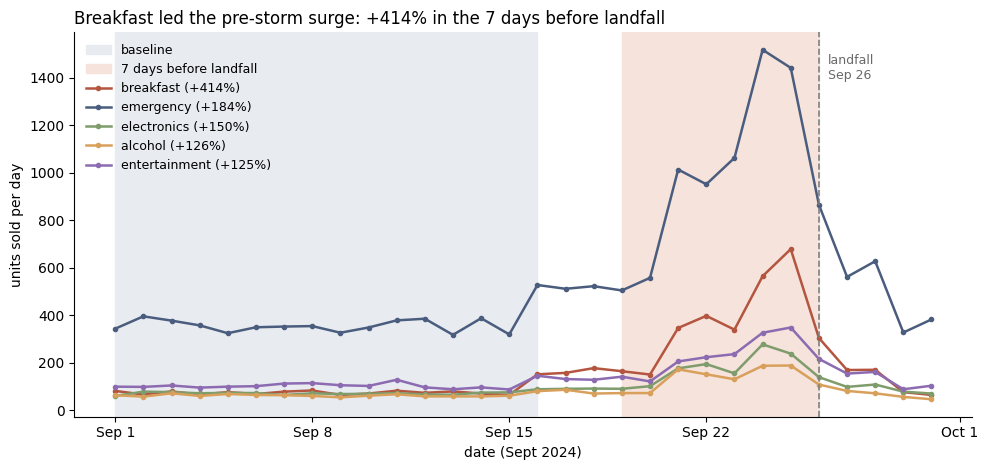

In [15]:
top5 = by_cat.head(5).index
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axvspan(BASELINE[0], BASELINE[1] + pd.Timedelta(days=1), color='#e8ebf0', label='baseline')
ax.axvspan(SURGE7[0], SURGE7[1] + pd.Timedelta(days=1), color='#f6e3dc', label='7 days before landfall')
for cat, color in zip(top5, ['#b4553f', '#4a5d7e', '#7f9c6c', '#d9a05b', '#8c6bb1']):
    ax.plot(cat_daily.index, cat_daily[cat], marker='o', ms=3, lw=1.8, color=color,
            label=f'{cat} (+{by_cat.loc[cat, "pct_increase_7d"]:.0f}%)')
ax.axvline(LANDFALL, ls='--', color='gray', lw=1.2)
ax.text(LANDFALL + pd.Timedelta(hours=8), cat_daily[top5].max().max() * 0.92, 'landfall\nSep 26', fontsize=9, color='dimgray')
ax.set_title(f'Breakfast led the pre-storm surge: +{by_cat.iloc[0]["pct_increase_7d"]:.0f}% in the 7 days before landfall',
             loc='left', fontsize=12)
ax.set_xlabel('date (Sept 2024)'); ax.set_ylabel('units sold per day')
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22])); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %-d'))
ax.legend(frameon=False, fontsize=9, loc='upper left')
for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

**Q1 answer:** In the 7 days before landfall (Sept 19–25), Florida stores sold **2,712 units a day, 2.46x the Sept 1–15 baseline of 1,103 (+146%)**. Buying concentrated in the last five days, Sept 21–25, at **2.89x**. **Breakfast** led every category (+414% over 7 days, 6.3x over the final 5), driven by Strawberry Pop-Tarts. **Emergency supplies** came second (+184%), then electronics, alcohol, and entertainment.

Snacks (+26%) and baby products (+57%) rose far less, so this wasn't just everything rising with foot traffic. Shoppers chose what to stock up on. The surprise is that a breakfast food beat emergency supplies, which matches Walmart's Pop-Tarts finding: shelf-stable food that needs no cooking or refrigeration.

## 7. Q2: The Pop-Tarts effect (SKU consolidation)

*After merging all Pop-Tart SKU variants, what is the true daily sales volume, and how does the fragmented view compare?*

The mapping (`SKU_TO_PRODUCT`) is defined as a table in the cleaning pipeline (Section 3), so it can be reviewed and committed. It covers every SKU in the data, and an assertion fails if a new SKU appears without a mapping.

In [16]:
sku_map = pd.Series(SKU_TO_PRODUCT, name='product').rename_axis('sku').reset_index()

unmapped = set(txns['sku']) - set(SKU_TO_PRODUCT)
assert not unmapped, f'SKUs with no mapping: {unmapped}'
assert set(sku_map['sku']) == set(catalog['sku']), 'mapping and catalog disagree'

txns['product'] = txns['sku'].map(SKU_TO_PRODUCT)
dated['product'] = dated['sku'].map(SKU_TO_PRODUCT)

units_by_sku = txns.groupby('sku')['quantity'].sum().sort_values(ascending=False)
units_by_product = txns.groupby('product')['quantity'].sum().sort_values(ascending=False)
assert units_by_sku.sum() == units_by_product.sum() == txns['quantity'].sum(), 'unit totals changed'
print(f'{txns["sku"].nunique()} SKUs ({txns["product_name"].nunique()} name spellings) -> {txns["product"].nunique()} products; '
      f'{units_by_product.sum():,} units before and after')

pt_skus = sku_map.loc[sku_map['product'] == 'Pop-Tarts Strawberry', 'sku'].tolist()
print('\nPop-Tarts mapping:'); display(raw_catalog.loc[raw_catalog['sku'].isin(pt_skus), ['sku', 'product_name', 'category', 'package_size']])

45 SKUs (63 name spellings) -> 20 products; 49,584 units before and after

Pop-Tarts mapping:


,sku,product_name,category,package_size
0,PT-12,pop-tarts strawberry,Breakfast Foods,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,4pk
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,4 pack


In [17]:
# True daily Pop-Tarts volume vs what any single SKU shows
pt_daily_sku = (dated[dated['product'] == 'Pop-Tarts Strawberry']
                  .groupby(['date', 'sku'])['quantity'].sum().unstack(fill_value=0))
pt_daily = pt_daily_sku.sum(axis=1)

summary = pd.DataFrame({
    'baseline (Sep 1-15)': [window_mean(pt_daily, BASELINE), window_mean(pt_daily_sku.max(axis=1), BASELINE)],
    '7 days pre-landfall': [window_mean(pt_daily, SURGE7), window_mean(pt_daily_sku.max(axis=1), SURGE7)],
    'peak day':            [pt_daily.max(), pt_daily_sku.max(axis=1).max()],
}, index=['consolidated (all 4 SKUs)', 'best single SKU']).round(1)
display(summary)

rank_before = units_by_sku.rank(ascending=False, method='min')
best_sku = units_by_sku[pt_skus].idxmax()
print(f'Best single Pop-Tart SKU ({best_sku}) ranks #{int(rank_before[best_sku])} of 45 SKUs; '
      f'consolidated Pop-Tarts rank #{int(units_by_product.rank(ascending=False, method="min")["Pop-Tarts Strawberry"])} of 20 products '
      f'with {units_by_product["Pop-Tarts Strawberry"]:,} units')

,baseline (Sep 1-15),7 days pre-landfall,peak day
consolidated (all 4 SKUs),73.3,376.9,678
best single SKU,27.0,122.9,240


Best single Pop-Tart SKU (PT-12) ranks #8 of 45 SKUs; consolidated Pop-Tarts rank #2 of 20 products with 5,198 units


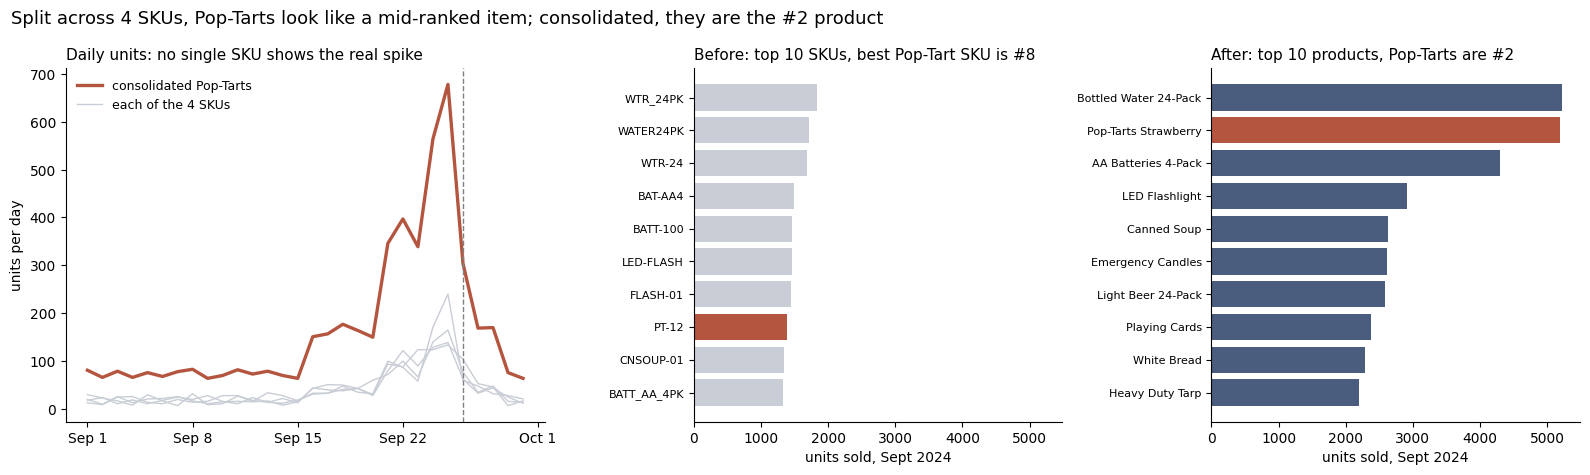

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1.3, 1, 1]})

# Left: daily trend, fragmented vs consolidated
for sku in pt_daily_sku.columns:
    axes[0].plot(pt_daily_sku.index, pt_daily_sku[sku], lw=1, color='#c9cdd6')
axes[0].plot(pt_daily.index, pt_daily, lw=2.4, color='#b4553f', label='consolidated Pop-Tarts')
axes[0].plot([], [], lw=1, color='#c9cdd6', label='each of the 4 SKUs')
axes[0].axvline(LANDFALL, ls='--', color='gray', lw=1)
axes[0].set_title('Daily units: no single SKU shows the real spike', loc='left', fontsize=11)
axes[0].set_ylabel('units per day'); axes[0].legend(frameon=False, fontsize=9)
axes[0].xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22]))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %-d'))

# Middle and right: top-10 ranking before vs after consolidation
largest_skus = set(pt_skus)
before = units_by_sku.head(10)[::-1]
after = units_by_product.head(10)[::-1]
axes[1].barh(before.index, before.values, color=['#b4553f' if s in largest_skus else '#c9cdd6' for s in before.index])
axes[1].set_title(f'Before: top 10 SKUs, best Pop-Tart SKU is #{int(rank_before[best_sku])}', loc='left', fontsize=11)
axes[2].barh(after.index, after.values, color=['#b4553f' if p == 'Pop-Tarts Strawberry' else '#4a5d7e' for p in after.index])
axes[2].set_title('After: top 10 products, Pop-Tarts are #2', loc='left', fontsize=11)
for ax in axes[1:]:
    ax.set_xlabel('units sold, Sept 2024'); ax.tick_params(axis='y', labelsize=8)
    ax.set_xlim(0, units_by_product.max() * 1.05)
for ax in axes:
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
fig.suptitle('Split across 4 SKUs, Pop-Tarts look like a mid-ranked item; consolidated, they are the #2 product',
             x=0.01, ha='left', fontsize=13)
plt.tight_layout(); plt.show()

**Q2 answer:** We consolidated **45 SKUs (63 name spellings) into 20 products** without changing the 49,584-unit total. Strawberry Pop-Tarts were split four ways. The best single SKU ranked only **#8**, but combined they are the **#2 product (5,198 units)**, just behind bottled water.

The true daily volume averaged **73 units a day in the baseline and 377 in the 7 days before landfall (5.1x)**, peaking at **678 on Sept 25**. A buyer looking at the best single SKU would see only about a third of that (123 a day pre-landfall, peaking at 240).

**Business impact:** Using the fragmented view, a replenishment planner would pre-position modest amounts of four "average" SKUs and probably cut the weakest ones. Using the consolidated view, Pop-Tarts are a top-two hurricane item and should be pushed to Florida distribution centers days before landfall, alongside water. The same fragmentation would also hide the size of the water, battery, and board-game surges.

## 8. Q3: Weather correlation and lag

*How do wind, precipitation, and pressure relate to daily sales, by category? Do purchases lead the weather?*

We have 30 days, one storm, and one weather station, so the correlations describe this storm. They aren't a forecasting model.

In [19]:
WEATHER_COLS = ['wind_max_kmh', 'precip_mm', 'pressure_min_hpa']

print(f'Total units vs weather, same day (n = {len(merged)} days):')
for col in WEATHER_COLS:
    print(f'  {col:<18} r = {merged["units"].corr(merged[col]):+.2f}')

print('\nLag: units today vs weather k days LATER (does buying lead the storm?)')
lag_rows = []
for k in range(0, 5):
    row = {'lag_days': k}
    for col in WEATHER_COLS:
        pair = pd.DataFrame({'u': merged['units'], 'w': merged[col].shift(-k)}).dropna()
        row[col] = pair['u'].corr(pair['w'])
    row['n_days'] = len(merged) - k
    lag_rows.append(row)
lags = pd.DataFrame(lag_rows).set_index('lag_days').round(2)
display(lags)
best_lag = lags['wind_max_kmh'].idxmax()
print(f'Strongest wind relationship: buying {best_lag} day(s) ahead, r = {lags.loc[best_lag, "wind_max_kmh"]:.2f}')

Total units vs weather, same day (n = 30 days):
  wind_max_kmh       r = +0.38
  precip_mm          r = -0.26
  pressure_min_hpa   r = -0.21

Lag: units today vs weather k days LATER (does buying lead the storm?)


,wind_max_kmh,precip_mm,pressure_min_hpa,n_days
lag_days,,,,
0,0.38,-0.26,-0.21,30
1,0.68,-0.22,-0.56,29
2,0.83,-0.20,-0.76,28
3,0.69,-0.16,-0.57,27
4,0.47,-0.11,-0.40,26


Strongest wind relationship: buying 2 day(s) ahead, r = 0.83


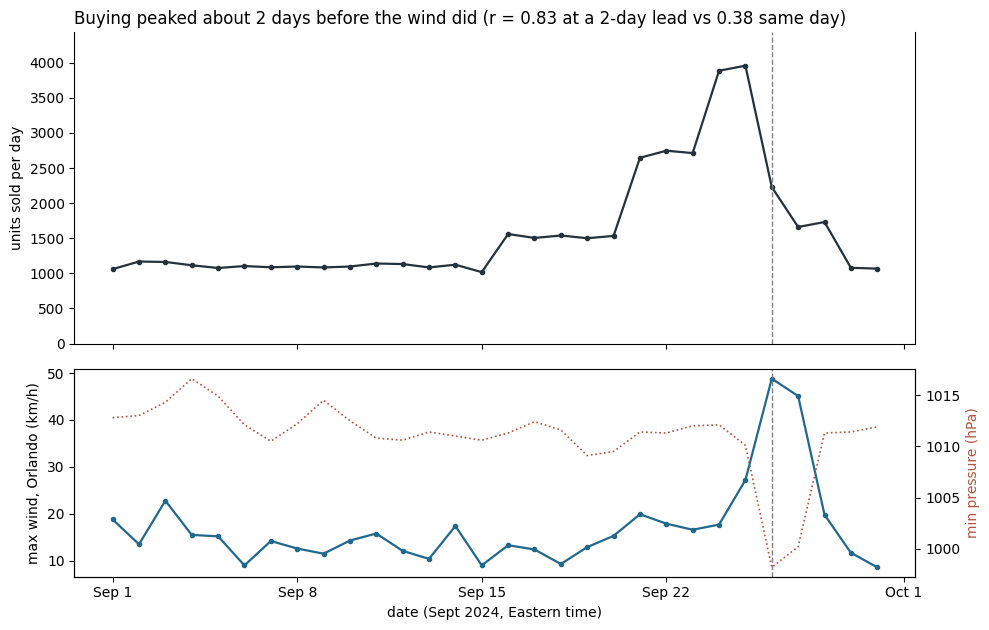

In [20]:
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True, gridspec_kw={'height_ratios': [3, 2]})
ax.plot(merged['date'], merged['units'], marker='o', ms=3, lw=1.6, color='#24323E')
ax.set_ylabel('units sold per day'); ax.set_ylim(0, merged['units'].max() * 1.12)
ax2.plot(merged['date'], merged['wind_max_kmh'], marker='o', ms=3, lw=1.6, color='#21688D', label='max wind (km/h)')
ax2b = ax2.twinx()
ax2b.plot(merged['date'], merged['pressure_min_hpa'], lw=1.2, ls=':', color='#b4553f', label='min pressure (hPa)')
ax2.set_ylabel('max wind, Orlando (km/h)'); ax2b.set_ylabel('min pressure (hPa)', color='#b4553f')
ax2.set_xlabel('date (Sept 2024, Eastern time)')
for a in (ax, ax2):
    a.axvline(LANDFALL, ls='--', color='gray', lw=1)
    a.spines['top'].set_visible(False)
ax.set_title(f'Buying peaked about {best_lag} days before the wind did '
             f'(r = {lags.loc[best_lag, "wind_max_kmh"]:.2f} at a {best_lag}-day lead vs {lags.loc[0, "wind_max_kmh"]:.2f} same day)',
             loc='left', fontsize=12)
ax2.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22])); ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %-d'))
plt.tight_layout(); plt.show()

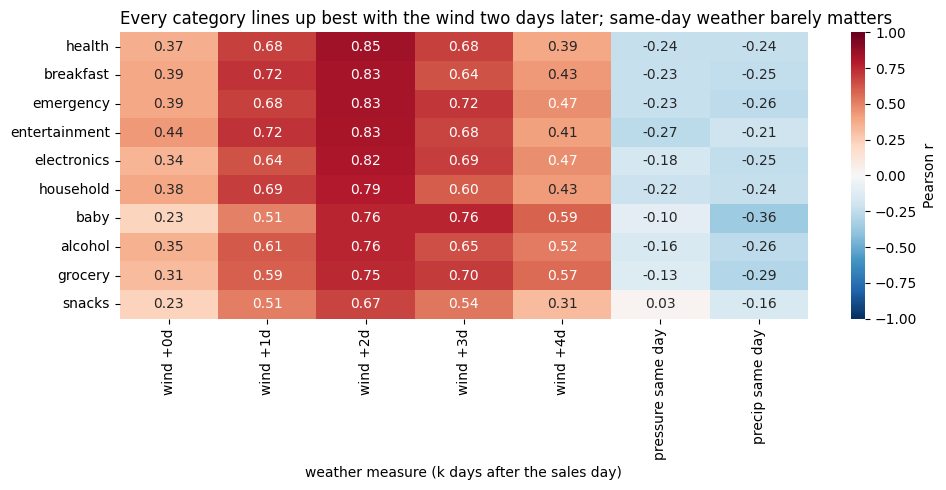

In [21]:
# By category: correlation of each category's daily units with wind 0-4 days later
cat_w = cat_daily.loc['2024-09-01':'2024-09-30'].join(weather.set_index('date'))
heat = pd.DataFrame({
    f'wind +{k}d': [cat_w[c].corr(cat_w['wind_max_kmh'].shift(-k)) for c in cat_daily.columns]
    for k in range(0, 5)
}, index=cat_daily.columns)
heat['pressure same day'] = [cat_w[c].corr(cat_w['pressure_min_hpa']) for c in cat_daily.columns]
heat['precip same day'] = [cat_w[c].corr(cat_w['precip_mm']) for c in cat_daily.columns]
heat = heat.sort_values('wind +2d', ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(heat, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax,
            cbar_kws={'label': 'Pearson r'})
ax.set_title('Every category lines up best with the wind two days later; same-day weather barely matters', loc='left', fontsize=12)
ax.set_xlabel('weather measure (k days after the sales day)'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

**Q3 answer:** We joined live Open-Meteo weather to all 30 sales days, with no rows lost. Hourly UTC readings were converted to Eastern time before daily aggregation; 128 of the 768 hourly readings move to a different calendar day when you do that.

Same-day correlations are weak: units vs. max wind r ≈ **0.38**, and vs. precipitation r ≈ **-0.26**. The relationship strengthens when sales are compared with wind **two days later**, rising to **r ≈ 0.83**. **Shoppers bought ahead of the storm, not during it.** By the time the wind arrived, buying was already falling.

Pressure shows the same pattern. Same-day r is only -0.21, but sales vs. pressure two days later is **r ≈ -0.76**: low pressure arrived two days after the buying peak. Every category follows the two-day lead. Health, breakfast, emergency, and entertainment are strongest (r = 0.83–0.85); snacks are weakest (0.67).

**Caveats:** This covers only 30 days (28 at the 2-day lag) and one storm. Orlando's weather stands in for all 12 stores, so the lag shows timing, not something you could build a forecast on.

## 9. Q4: Store-level geographic patterns

*Did stores closer to the storm's path surge earlier and more?*

We use the same baseline and 5-day surge windows as Q1. Distance is measured to Helene's landfall point near Perry, FL (30.0 N, 84.0 W). For **timing**, we record the first day each store's sales passed 2x its own baseline.

In [22]:
LANDFALL_LAT, LANDFALL_LON = 30.0, -84.0

def haversine_miles(lat1, lon1, lat2, lon2):
    R = 3958.8
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin(np.radians(lat2 - lat1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * R * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

store_daily = dated.groupby(['date', 'store_id'])['quantity'].sum().unstack(fill_value=0)
store_base = store_daily.loc[BASELINE[0]:BASELINE[1]].mean()
store_q4 = pd.DataFrame({
    'baseline_avg': store_base,
    'surge_avg': store_daily.loc[SURGE5[0]:SURGE5[1]].mean(),
    'transactions': dated.groupby('store_id').size(),
})
store_q4['multiple'] = store_q4['surge_avg'] / store_q4['baseline_avg']
# Surge timing: first day after the baseline when units passed 2x the store's own baseline
after_base = store_daily.loc['2024-09-16':'2024-09-26']
store_q4['first_2x_day'] = (after_base.ge(2 * store_base)).idxmax()
store_q4 = store_q4.join(stores.set_index('store_id')[['city', 'region', 'latitude', 'longitude']])
store_q4['miles_to_landfall'] = haversine_miles(store_q4['latitude'], store_q4['longitude'], LANDFALL_LAT, LANDFALL_LON)

# Outliers: more than 2 standard deviations from the mean multiple
z = (store_q4['multiple'] - store_q4['multiple'].mean()) / store_q4['multiple'].std()
store_q4['outlier'] = z.abs() > 2
store_q4 = store_q4.sort_values('miles_to_landfall')
display(store_q4[['city', 'region', 'miles_to_landfall', 'transactions', 'baseline_avg', 'surge_avg',
                  'multiple', 'first_2x_day', 'outlier']].assign(first_2x_day=lambda d: d['first_2x_day'].dt.strftime('%b %d')).round(2))
print(f'correlation of distance with surge multiple: r = {store_q4["miles_to_landfall"].corr(store_q4["multiple"]):+.2f}')

,city,region,miles_to_landfall,transactions,baseline_avg,surge_avg,multiple,first_2x_day,outlier
store_id,,,,,,,,,
FL-619,Tallahassee,Panhandle,34.61,1981,86.13,257.4,2.99,Sep 21,False
FL-078,Gainesville,North,103.26,2001,92.40,256.2,2.77,Sep 22,False
FL-412,Jacksonville,North,141.91,2028,89.47,262.8,2.94,Sep 21,False
FL-105,Tampa,West,169.55,2043,91.73,278.6,3.04,Sep 21,False
FL-445,St. Petersburg,West,174.80,2074,94.53,272.8,2.89,Sep 21,False
FL-302,Lakeland,Central,183.55,2123,96.27,286.0,2.97,Sep 21,False
FL-156,Daytona Beach,East,186.97,2074,94.93,268.8,2.83,Sep 21,False
FL-239,Orlando,Central,187.48,2010,93.80,245.2,2.61,Sep 21,False
FL-710,Pensacola,Panhandle,194.27,2066,93.40,268.2,2.87,Sep 21,False


correlation of distance with surge multiple: r = +0.31


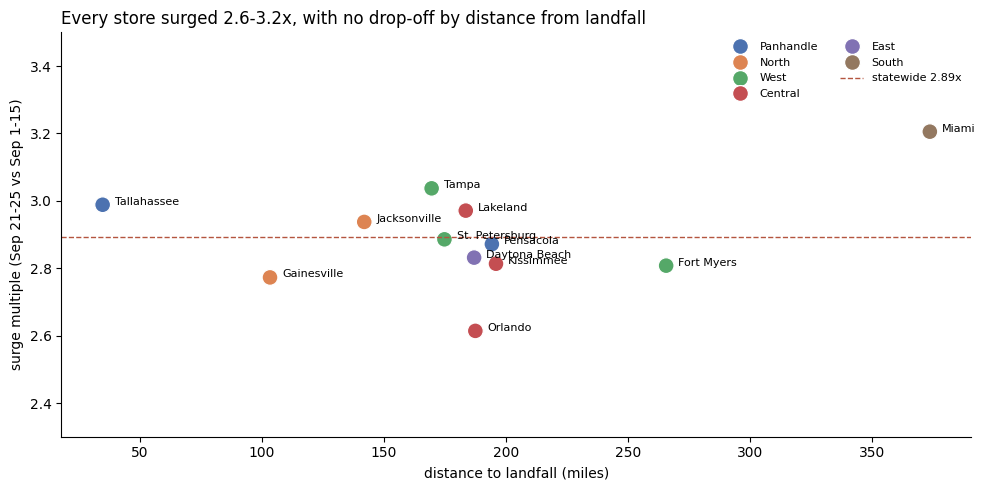

In [23]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=store_q4, x='miles_to_landfall', y='multiple', hue='region', s=130, ax=ax, palette='deep')
for sid, row in store_q4.iterrows():
    ax.annotate(f'{row["city"]}', (row['miles_to_landfall'] + 5, row['multiple']), fontsize=8)
ax.axhline(q1_multiple, color='#b4553f', ls='--', lw=1, label=f'statewide {q1_multiple:.2f}x')
ax.set_title('Every store surged 2.6-3.2x, with no drop-off by distance from landfall', loc='left', fontsize=12)
ax.set_xlabel('distance to landfall (miles)'); ax.set_ylabel('surge multiple (Sep 21-25 vs Sep 1-15)')
ax.set_ylim(2.3, 3.5); ax.legend(frameon=False, fontsize=8, ncol=2)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

**Q4 answer:** Every store surged between **2.6x and 3.2x**, close to the 2.89x statewide figure, and distance didn't predict the size of the surge. Tallahassee, 35 miles from landfall, was 2.99x; Miami, 374 miles away, was 3.21x. Distance and multiple correlate at r ≈ **+0.31**. That's slightly positive, the opposite of what proximity would predict, and it's driven by Miami.

Timing was also nearly uniform: stores first passed 2x their baseline on almost the same day: 11 of 12 stores on **Sept 21**, and Gainesville on Sept 22. **Miami (3.21x)**, the farthest store, is the only outlier (more than 2 standard deviations above the mean); Orlando was lowest at 2.61x. All 12 stores have about 2,100 transactions, so the store-level numbers aren't small-sample noise.

**Interpretation:** The forecast cone covered the whole state for days, so the buying response was statewide. Walmart should pre-position supplies for every Florida store, not just those on the predicted path.

## 10. Q5: Board games, signal or artifact?

*The entertainment category shows about a +250% increase. Is that real board-game demand or a data artifact?*

We test four possible artifacts, using the SQLite database (queried with `sqlite3` + SQL) and cross-checking against the transaction CSV:

1. **Headline check:** Where does the +250% come from, and does it hold up?
2. **Category lumping:** Is "entertainment" really board games, or other products lumped in?
3. **SKU miscoding:** Are board-game SKUs coded under other categories, or other products coded as entertainment?
4. **Inventory reporting lag:** Did board games physically leave shelves when sales say they did?

Finally, we compare entertainment's surge to the surge in **total store traffic**.

In [24]:
# 5.1 Headline: entertainment units by day from the SQLite summary table.
# Dates come in two formats ('2024-09-14' and '20240914'), so normalize them in SQL before grouping.
ent_sql = '''
SELECT CASE WHEN length(date) = 8
            THEN substr(date, 1, 4) || '-' || substr(date, 5, 2) || '-' || substr(date, 7, 2)
            ELSE date END                                     AS day,
       SUM(CASE WHEN category = 'Entertainment' THEN total_units END) AS entertainment_units,
       SUM(total_units)                                       AS all_units
FROM daily_sales_summary
GROUP BY day
ORDER BY day
'''
db_daily = pd.read_sql(ent_sql, con, parse_dates=['day']).set_index('day')
db_daily['ent_share'] = db_daily['entertainment_units'] / db_daily['all_units']

def pct(s, w):  # % change vs baseline
    return (window_mean(s, w) / window_mean(s, BASELINE) - 1) * 100

PEAK2 = (pd.Timestamp('2024-09-24'), pd.Timestamp('2024-09-25'))
headline = pd.DataFrame({
    'entertainment': [pct(db_daily['entertainment_units'], w) for w in (SURGE7, SURGE5, PEAK2)],
    'all categories': [pct(db_daily['all_units'], w) for w in (SURGE7, SURGE5, PEAK2)],
}, index=['7 days pre-landfall', 'Sep 21-25', 'peak 2 days (Sep 24-25)']).round(0)
print('% increase vs Sep 1-15 baseline (SQLite daily_sales_summary):'); display(headline)
print(f'Entertainment share of all units: baseline {window_mean(db_daily["ent_share"], BASELINE):.1%}, '
      f'7 days pre-landfall {window_mean(db_daily["ent_share"], SURGE7):.1%}')

% increase vs Sep 1-15 baseline (SQLite daily_sales_summary):


,entertainment,all categories
7 days pre-landfall,145.0,112.0
Sep 21-25,189.0,144.0
peak 2 days (Sep 24-25),267.0,200.0


Entertainment share of all units: baseline 9.6%, 7 days pre-landfall 11.0%


In [25]:
# 5.2 + 5.3 Category audit: what is actually inside 'entertainment', and is anything miscoded?
cat_audit = (txns.groupby(['category', 'product'])
                 .agg(skus=('sku', 'nunique'), units=('quantity', 'sum')))
ent_products = cat_audit.loc['entertainment']
print("Products inside the 'entertainment' category:"); display(ent_products)

game_skus = sku_map.loc[sku_map['product'].isin(['Monopoly Board Game', 'Playing Cards']), 'sku']
print("Categories that board-game / card SKUs were recorded under (raw spellings):")
display(raw_txns[raw_txns['sku'].isin(game_skus)].groupby(['sku', 'category']).size().unstack(fill_value=0))

print('Catalog categories for those SKUs:')
display(raw_catalog.loc[raw_catalog['sku'].isin(game_skus), ['sku', 'product_name', 'category']])

Products inside the 'entertainment' category:


,skus,units
product,,
Monopoly Board Game,3,2017
Playing Cards,2,2381


Categories that board-game / card SKUs were recorded under (raw spellings):


category,ENTERTAINMENT,Entertainment,Games & Entertainment,entertainment
sku,,,,
BG-MONO,110,112,100,113
CARDS-01,149,158,124,156
GAME-MONO,113,106,122,125
MONOPOLY-01,102,114,137,88
PLAYCARD-STD,130,159,164,159


Catalog categories for those SKUs:


,sku,product_name,category
14,BG-MONO,Monopoly Board Game,ENTERTAINMENT
15,MONOPOLY-01,Monopoly Board Game,entertainment
16,GAME-MONO,Board Game - Monopoly,ENTERTAINMENT
17,CARDS-01,Playing Cards,ENTERTAINMENT
18,PLAYCARD-STD,PLAYING CARDS,entertainment


In [26]:
# Board games vs playing cards vs the whole store, from the transactions
game_daily = (dated[dated['product'].isin(['Monopoly Board Game', 'Playing Cards'])]
                .groupby(['date', 'product'])['quantity'].sum().unstack(fill_value=0))
compare = pd.DataFrame({
    'Monopoly (board game)': [pct(game_daily['Monopoly Board Game'], w) for w in (SURGE7, SURGE5)],
    'Playing cards': [pct(game_daily['Playing Cards'], w) for w in (SURGE7, SURGE5)],
    'All products': [pct(daily_units, w) for w in (SURGE7, SURGE5)],
}, index=['7 days pre-landfall', 'Sep 21-25']).round(0)
print('% increase vs baseline (transactions CSV):'); display(compare)

# Did basket size or price change? (a miscoded bulk SKU would show up here)
mono = dated[dated['product'] == 'Monopoly Board Game'].copy()
mono['period'] = np.select([mono['date'] <= BASELINE[1], mono['date'].between(*SURGE5)], ['baseline', 'surge'], 'other')
display(mono.groupby('period').agg(transactions=('quantity', 'size'), avg_qty=('quantity', 'mean'),
                                   max_qty=('quantity', 'max'), avg_price=('unit_price', 'mean')).round(2))

% increase vs baseline (transactions CSV):


,Monopoly (board game),Playing cards,All products
7 days pre-landfall,160.0,99.0,146.0
Sep 21-25,214.0,126.0,189.0


,transactions,avg_qty,max_qty,avg_price
period,,,,
baseline,423,1.52,2,20.02
other,412,1.51,2,19.98
surge,447,1.51,2,20.01


In [27]:
# 5.4 Inventory: did board games physically leave the shelves? (SQLite inventory_levels)
inv_sql = '''
SELECT i.date,
       CASE WHEN i.sku IN ('BG-MONO','MONOPOLY-01','GAME-MONO') THEN 'Monopoly'
            WHEN i.sku IN ('CARDS-01','PLAYCARD-STD')           THEN 'Playing cards'
            WHEN i.sku IN ('MISC-001','LEGACY-PT','UNKNOWN-99','OLD-BATT-50') THEN 'Not in catalog'
            ELSE 'All other products' END                       AS product_group,
       AVG(i.units_on_hand)                                     AS avg_on_hand,
       AVG(CASE WHEN i.units_on_hand < i.reorder_point THEN 1.0 ELSE 0 END) AS share_below_reorder,
       COUNT(*)                                                 AS records
FROM inventory_levels i
GROUP BY i.date, product_group
'''
inv_daily = pd.read_sql(inv_sql, con, parse_dates=['date'])
inv_daily['period'] = np.select([inv_daily['date'] <= BASELINE[1], inv_daily['date'].between(*SURGE5)],
                                ['baseline', 'Sep 21-25'], 'other')
inv_summary = (inv_daily[inv_daily['period'] != 'other']
               .groupby(['product_group', 'period'])
               .apply(lambda g: pd.Series({'avg_on_hand': np.average(g['avg_on_hand'], weights=g['records']),
                                           'share_below_reorder': np.average(g['share_below_reorder'], weights=g['records'])}),
                      include_groups=False)
               .unstack().round(2))
display(inv_summary)

avg_on_hand          share_below_reorder         
period               Sep 21-25 baseline           Sep 21-25 baseline
product_group                                                       
All other products       32.86    80.59                0.52     0.18
Monopoly                 33.73    84.30                0.56     0.14
Not in catalog           34.93    79.05                0.54     0.19
Playing cards            31.38    80.96                0.62     0.20

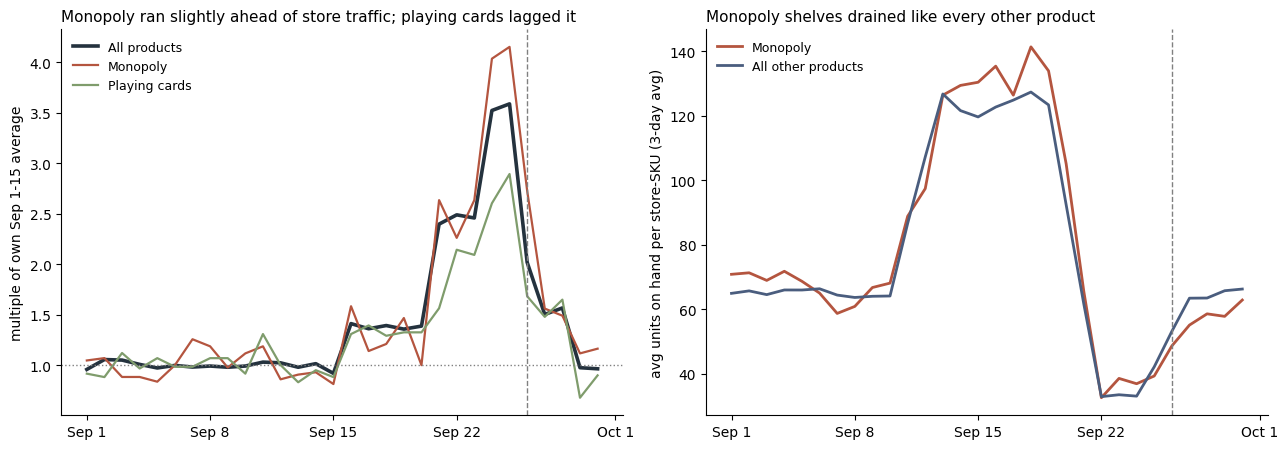

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# Left: indexed daily units, board games vs cards vs whole store
idx = pd.DataFrame({
    'Monopoly': game_daily['Monopoly Board Game'] / window_mean(game_daily['Monopoly Board Game'], BASELINE),
    'Playing cards': game_daily['Playing Cards'] / window_mean(game_daily['Playing Cards'], BASELINE),
    'All products': daily_units / base_avg,
})
for col, color, lw in [('All products', '#24323E', 2.6), ('Monopoly', '#b4553f', 1.6), ('Playing cards', '#7f9c6c', 1.6)]:
    axes[0].plot(idx.index, idx[col], color=color, lw=lw, label=col)
axes[0].axhline(1, ls=':', color='gray', lw=1); axes[0].axvline(LANDFALL, ls='--', color='gray', lw=1)
axes[0].set_title('Monopoly ran slightly ahead of store traffic; playing cards lagged it', loc='left', fontsize=11)
axes[0].set_ylabel('multiple of own Sep 1-15 average'); axes[0].legend(frameon=False, fontsize=9)
axes[0].xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22])); axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %-d'))

# Right: average units on hand, Monopoly vs everything else
inv_plot = inv_daily[inv_daily['product_group'].isin(['Monopoly', 'All other products'])]
for grp, color in [('Monopoly', '#b4553f'), ('All other products', '#4a5d7e')]:
    g = inv_plot[inv_plot['product_group'] == grp].sort_values('date')
    axes[1].plot(g['date'], g['avg_on_hand'].rolling(3, center=True, min_periods=1).mean(), color=color, lw=2, label=grp)
axes[1].axvline(LANDFALL, ls='--', color='gray', lw=1)
axes[1].set_title('Monopoly shelves drained like every other product', loc='left', fontsize=11)
axes[1].set_ylabel('avg units on hand per store-SKU (3-day avg)'); axes[1].legend(frameon=False, fontsize=9)
axes[1].xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22])); axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %-d'))
for ax in axes:
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

**Q5 findings**

1. **The +250% is a peak-window number.** In the SQLite summary, entertainment is up **+267%** on the peak two days (Sept 24–25) but **+145%** over the 7 days before landfall. In the same table, total units across all categories rose **+112%** over those 7 days. The SQLite summary shows a smaller store-wide rise than the transaction file (+146% in Q1), so we compare each category only with totals from its own source. Entertainment's share of units rose only modestly (**9.6% → 11.0%**). Most of the "surge" is simply more shoppers in the store.
2. **Category lumping is real, but it doesn't create the surge.** "Entertainment" combines Monopoly and playing cards under four spellings ("Games & Entertainment", "ENTERTAINMENT", and so on). Monopoly rose **+214%** and playing cards **+126%**, against **+189%** for the whole store (transactions, Sept 21–25). So board games ran only slightly ahead of overall traffic.
3. **No SKU miscoding.** All three Monopoly SKUs and both card SKUs are recorded only under entertainment spellings. No other product is coded as entertainment. Basket size and price didn't change (about 1.5 per transaction at about $20), so no bulk or mispriced SKU is inflating units.
4. **Not a reporting lag.** Monopoly inventory fell from about **84 to 34 units on hand per store-SKU** during the surge, and **56%** of records were below the reorder point (52% for all other products). That's the same drawdown as every other product. The units physically left the shelves. The four orphan inventory SKUs (LEGACY-PT, MISC-001, UNKNOWN-99, OLD-BATT-50) are a separate data-quality issue that doesn't touch entertainment.

**Verdict: a genuine but ordinary signal.** Board games sold more because hurricane-week stores sold more of almost everything. They weren't a special hurricane item the way Pop-Tarts, water, and batteries were.

**Recommendation:** Don't order +250% extra board games. Scale board-game stock with the expected **store-wide** traffic uplift (about 2.5–3x for the final pre-landfall days), as for any regular item, and spend the incremental truck space on breakfast and emergency supplies, which outperformed traffic. Re-check after the next storm before treating board games as a hurricane item.

## 11. Recommendation summary

| Question | Finding | What Walmart should do |
|---|---|---|
| Q1 | Units rose 2.89x in the final 5 days; breakfast led at 6.3x, emergency supplies next | Pre-stock breakfast and emergency categories first |
| Q2 | Pop-Tarts are the #2 product once 4 SKUs are merged | Plan replenishment on consolidated products, not SKUs |
| Q3 | Buying peaks about 2 days before the strongest wind | Have stock in stores at least 3 days before forecast landfall |
| Q4 | Every store surged 2.6–3.2x regardless of distance | Pre-position for the whole state, not just the cone |
| Q5 | Board-game rise is mostly store traffic, not a special signal | Scale board games with traffic; don't over-order |

## 12. Reflection

### 1. Data quality impact
The most consequential issue was the **mixed timestamp formats**: five formats, including both `09/05/2024` and ISO dates. Reading ambiguous dates day-first would have moved 5,730 of our 24,521 dated rows (23%) outside September, since 09/05 becomes May 9. Run through the same pipeline, the pre-storm baseline drops from 1,103 to 367 units a day, and the pre-landfall surge goes from **2.89x to 8.69x**, three times the real number, with no error to warn us. That's why the pipeline now parses month-first explicitly and a daily-orders sanity chart sits directly after cleaning.

### 2. ETL trade-offs
We dropped all 130 rows with quantity ≤ 0 (−241 units). The alternative was to keep them as returns and net them against sales. That wouldn't have changed anything we reported: the surge is 2.89x either way. Returns were about 0.5% of transactions on a typical day all month (0.35–0.56% on the middle half of days), so they rose with store traffic, not because of the storm. A second decision was **joining weather by Eastern-time date rather than UTC date**. Grouping by UTC moves 128 of the 768 hourly readings onto the next day. We tested both ways: the two-day lead holds either way (r = 0.83), because Helene's wind stayed high for more than a day, but same-day wind correlation drops slightly (0.38 to 0.37). Eastern time is still correct because it matches when shoppers bought, and it would matter more for short, sharp weather events. We'd make both calls again. The lesson is to run a decision both ways first and save the debate for the ones that actually change a number.

### 3. Pipeline trust
We agree with the CDO. Our most fragile point was the **hand-off between cleaning and analysis**. For most of the project, the cleaning functions lived in the checkpoint notebook, and the analysis notebooks loaded a saved `transactions_clean.csv`. Several fixes (the category map, Tallahassee's coordinates, day boundaries) were made inside analysis cells. Nothing guaranteed the CSV matched the code, and one store-level calculation briefly understated surges by about 29% because of a day-boundary bug. In this final notebook every fix is in the pipeline, which runs from the raw files, and `validate_clean()` stops execution if the row count, unit total, or store IDs drift. The model (a ratio of two averages) was never the risk.

### 4. Business vs. data
For board games, the statistics alone looked like a strong signal: +250% at the peak. But the business risk is asymmetric. Over-ordering a $20 non-essential item ties up truck space that should carry water and Pop-Tarts. So we asked whether board games beat **overall traffic**, not just their own baseline, and whether the inventory confirmed the sales. Board games only slightly beat traffic and the inventory matched, so we recommended scaling them with traffic rather than a special buy. With more time we'd want several storms, and store-level inventory before and after restocks, to separate "sold out" from "didn't want it." If board games beat traffic again in another storm, we'd change our recommendation.

### 5. Team collaboration
We split the work by pipeline stage. Karen owned cleaning, the decision log, Q1, Q4, and Q5; Zach owned the weather API and join, Q2, and Q3, and each person reviewed the other's questions. What cost us the most time was **waiting on reviews**: our charter's only timing rule was "respond ASAP," and with one weekly meeting a review could slip by days. With another week, we'd set a 24-hour review window and have the owner state exactly what to check (for example, "confirm 2.89x and 25,402 rows").

Zach's most valuable contribution was building the Open-Meteo pull with retries and proving the sales-weather join lost no rows. Karen's most valuable contribution was keeping the decision log that recorded every cleaning choice in plain language with its row counts.